# 06_final_comparison_v3.ipynb

## 목적
v1 → v2 → v3 피처 엔지니어링 3단계와 하이퍼파라미터 튜닝 전 과정의 결과를 종합하여
최종 결론을 도출합니다.

## 목차
1. 환경 세팅 및 결과 로드
2. 버전별 성능 비교 (v1 vs v2 vs v3)
3. 튜닝 방법별 성능 비교
4. 전체 실험 종합 비교
5. 피처 중요도 분석
6. 최종 결론


## 1. 환경 세팅 및 결과 로드

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import lightgbm as lgb
import os

from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, f1_score
)

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:.4f}'.format
print('임포트 완료')


임포트 완료


In [2]:
# 분할 데이터 로드 (피처 중요도 분석용)
X_train = pd.read_csv('../data/processed/X_train_v3.csv')
X_val   = pd.read_csv('../data/processed/X_val_v3.csv')
y_train = pd.read_csv('../data/processed/y_train_v3.csv').squeeze()
y_val   = pd.read_csv('../data/processed/y_val_v3.csv').squeeze()

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}')


X_train: (914921, 54), X_val: (228731, 54)


## 2. 버전별 성능 비교 (v1 vs v2 vs v3)

In [3]:
version_results = pd.DataFrame([
    {'버전': 'v1 (RFM 16개)',        '최고 모델': 'CatBoost', 'Accuracy': 0.7687, 'AUC': 0.8485, 'F1': 0.7723},
    {'버전': 'v2 (트렌드 22개)',      '최고 모델': 'CatBoost', 'Accuracy': 0.7687, 'AUC': 0.8486, 'F1': 0.7728},
    {'버전': 'v3 (시퀀스 26개)',      '최고 모델': 'CatBoost', 'Accuracy': 0.7687, 'AUC': 0.8486, 'F1': 0.7728},
])

print('--- 버전별 최고 성능 비교 ---')
print(version_results.to_string(index=False))


--- 버전별 최고 성능 비교 ---
          버전    최고 모델  Accuracy    AUC     F1
v1 (RFM 16개) CatBoost    0.7687 0.8485 0.7723
v2 (트렌드 22개) CatBoost    0.7687 0.8486 0.7728
v3 (시퀀스 26개) CatBoost    0.7687 0.8486 0.7728


C:\Users\09048\AppData\Local\Temp\ipykernel_26976\2628313366.py:22: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\2628313366.py:22: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\2628313366.py:22: UserWarning: Glyph 47116 (\N{HANGUL SYLLABLE REN}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\2628313366.py:22: UserWarning: Glyph 46300 (\N{HANGUL SYLLABLE DEU}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\2628313366.py:22: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\2628313366.py:22: UserWarning: Glyph 53248 (\N{HANGUL SYLLABLE KWEON}) missing from font(s) Arial.
  plt.tight_

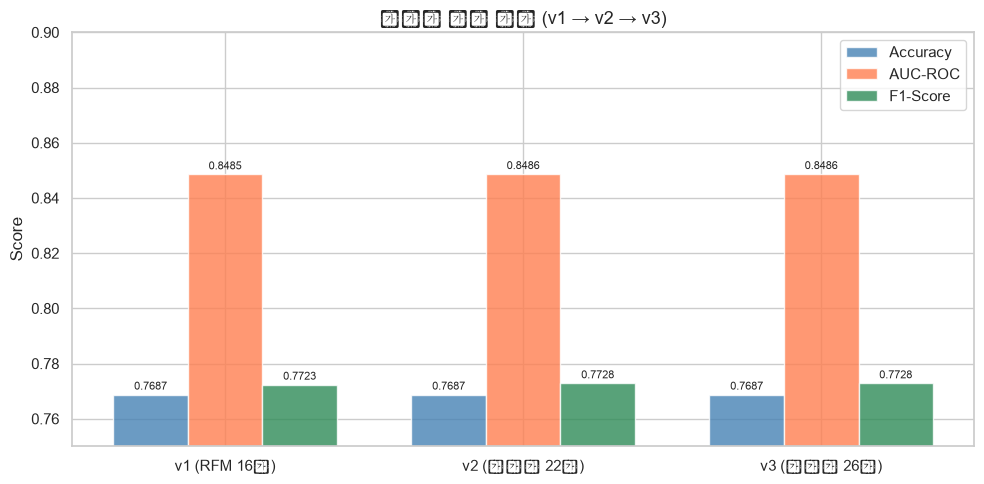

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(version_results))
width = 0.25

bars1 = ax.bar(x - width, version_results['Accuracy'], width, label='Accuracy', color='steelblue', alpha=0.8)
bars2 = ax.bar(x,          version_results['AUC'],      width, label='AUC-ROC',  color='coral',     alpha=0.8)
bars3 = ax.bar(x + width,  version_results['F1'],       width, label='F1-Score', color='seagreen',  alpha=0.8)

ax.set_xticks(x)
ax.set_xticklabels(version_results['버전'])
ax.set_ylim(0.75, 0.90)
ax.set_title('버전별 성능 비교 (v1 → v2 → v3)', fontsize=13)
ax.set_ylabel('Score')
ax.legend()

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()


## 3. 튜닝 방법별 성능 비교

In [5]:
tuning_results = pd.DataFrame([
    {'방법': '기본 파라미터 (베이스라인)', '모델': 'CatBoost',  'AUC': 0.8486, '비고': 'v3 최고 성능'},
    {'방법': '기본 파라미터 (베이스라인)', '모델': 'XGBoost',   'AUC': 0.8482, '비고': ''},
    {'방법': '기본 파라미터 (베이스라인)', '모델': 'LightGBM',  'AUC': 0.8480, '비고': ''},
    {'방법': 'RandomizedSearchCV',      '모델': 'XGBoost',   'AUC': 0.8482, '비고': 'n_iter=20, 30% 샘플'},
    {'방법': 'RandomizedSearchCV',      '모델': 'LightGBM',  'AUC': 0.8477, '비고': 'n_iter=20, 30% 샘플'},
    {'방법': 'Optuna (베이지안)',        '모델': 'LightGBM',  'AUC': 0.8463, '비고': 'n_trials=30, 30% 샘플, CV AUC'},
    {'방법': 'Optuna (베이지안)',        '모델': 'XGBoost',   'AUC': 0.8462, '비고': 'n_trials=30, 30% 샘플, CV AUC'},
])

print('--- 튜닝 방법별 AUC 비교 ---')
print(tuning_results.to_string(index=False))


--- 튜닝 방법별 AUC 비교 ---
                방법       모델    AUC                          비고
   기본 파라미터 (베이스라인) CatBoost 0.8486                    v3 최고 성능
   기본 파라미터 (베이스라인)  XGBoost 0.8482                            
   기본 파라미터 (베이스라인) LightGBM 0.8480                            
RandomizedSearchCV  XGBoost 0.8482           n_iter=20, 30% 샘플
RandomizedSearchCV LightGBM 0.8477           n_iter=20, 30% 샘플
     Optuna (베이지안) LightGBM 0.8463 n_trials=30, 30% 샘플, CV AUC
     Optuna (베이지안)  XGBoost 0.8462 n_trials=30, 30% 샘플, CV AUC


C:\Users\09048\AppData\Local\Temp\ipykernel_26976\3026256889.py:21: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\3026256889.py:21: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\3026256889.py:21: UserWarning: Glyph 54028 (\N{HANGUL SYLLABLE PA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\3026256889.py:21: UserWarning: Glyph 46972 (\N{HANGUL SYLLABLE RA}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\3026256889.py:21: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\3026256889.py:21: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) Arial.
  plt.tight_layou

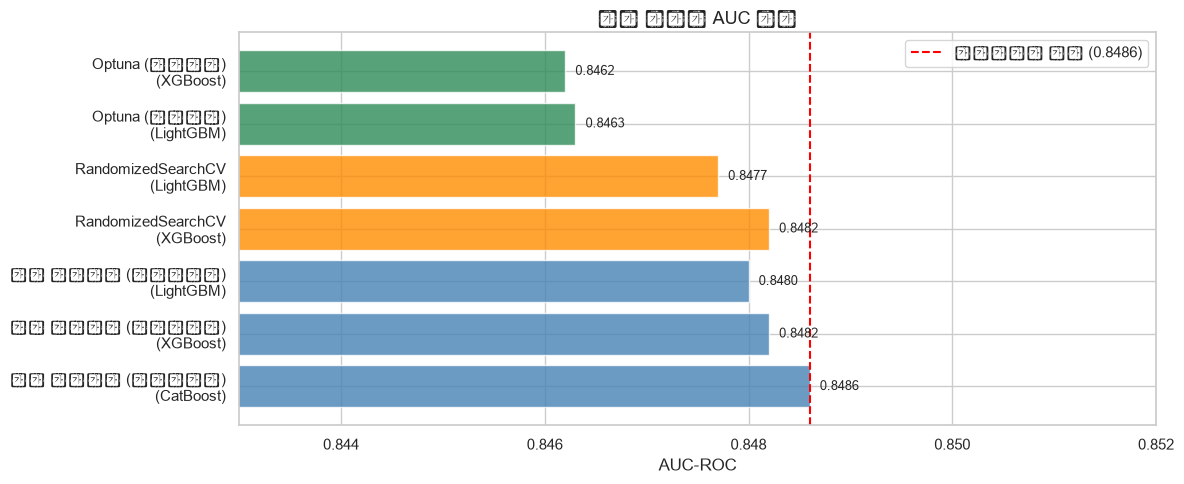

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

colors = {
    '기본 파라미터 (베이스라인)': 'steelblue',
    'RandomizedSearchCV': 'darkorange',
    'Optuna (베이지안)': 'seagreen'
}

for i, row in tuning_results.iterrows():
    ax.barh(f"{row['방법']}\n({row['모델']})",
            row['AUC'],
            color=colors[row['방법']],
            alpha=0.8)
    ax.text(row['AUC'] + 0.0001, i, f"{row['AUC']:.4f}", va='center', fontsize=9)

ax.axvline(x=0.8486, color='red', linestyle='--', lw=1.5, label='베이스라인 최고 (0.8486)')
ax.set_xlim(0.843, 0.852)
ax.set_title('튜닝 방법별 AUC 비교', fontsize=13)
ax.set_xlabel('AUC-ROC')
ax.legend()
plt.tight_layout()
plt.show()


## 4. 전체 실험 종합 비교

In [7]:
all_results = pd.DataFrame([
    {'실험 단계': 'v1 베이스라인',           '시도 내용': 'RFM 16개 피처',            '최고 AUC': 0.8485, '변화': '-'},
    {'실험 단계': 'v2 피처 추가',            '시도 내용': '트렌드 피처 +6개',          '최고 AUC': 0.8486, '변화': '+0.0001'},
    {'실험 단계': 'v2 하이퍼파라미터 튜닝',   '시도 내용': 'RandomizedSearchCV',       '최고 AUC': 0.8482, '변화': '-0.0004'},
    {'실험 단계': 'v3 피처 추가',            '시도 내용': '시퀀스 피처 +5개',          '최고 AUC': 0.8486, '변화': '+0.0000'},
    {'실험 단계': 'v3 하이퍼파라미터 튜닝',   '시도 내용': 'Optuna 베이지안 최적화',    '최고 AUC': 0.8463, '변화': '-0.0023'},
])

print('--- 전체 실험 종합 ---')
print(all_results.to_string(index=False))


--- 전체 실험 종합 ---
        실험 단계              시도 내용  최고 AUC      변화
     v1 베이스라인         RFM 16개 피처  0.8485       -
     v2 피처 추가         트렌드 피처 +6개  0.8486 +0.0001
v2 하이퍼파라미터 튜닝 RandomizedSearchCV  0.8482 -0.0004
     v3 피처 추가         시퀀스 피처 +5개  0.8486 +0.0000
v3 하이퍼파라미터 튜닝    Optuna 베이지안 최적화  0.8463 -0.0023


## 5. 피처 중요도 분석

v3 데이터 기준 LightGBM 베이스라인 모델의 피처 중요도를 확인합니다.
EDA에서 발견한 상관관계와 모델이 실제로 중요하게 본 피처가 일치하는지 교차 검증합니다.


In [8]:
# LightGBM 기본 파라미터로 재학습 (피처 중요도 추출용)
model = lgb.LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)
model.fit(X_train, y_train)

importance_df = pd.DataFrame({
    'feature'   : X_train.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)
importance_df['rank'] = importance_df.index + 1

print('--- 피처 중요도 Top 15 ---')
print(importance_df[['rank','feature','importance']].head(15).to_string(index=False))


--- 피처 중요도 Top 15 ---
 rank                        feature  importance
    1                        recency         401
    2          std_purchase_interval         313
    3                            age         275
    4          avg_purchase_interval         269
    5                      price_max         148
    6                unique_articles         125
    7          interval_acceleration         115
    8      club_member_status_ACTIVE          96
    9 index_group_name_Baby/Children          95
   10                      price_sum          90
   11                    interval_t2          89
   12                    interval_t3          75
   13            frequency_last_180d          70
   14                    interval_t4          59
   15                         Active          58


C:\Users\09048\AppData\Local\Temp\ipykernel_26976\1526116399.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=top20, ax=axes[0], palette='Blues_r')
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\1526116399.py:27: UserWarning: Glyph 54588 (\N{HANGUL SYLLABLE PI}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\1526116399.py:27: UserWarning: Glyph 52376 (\N{HANGUL SYLLABLE CEO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\1526116399.py:27: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_26976\1526116399.py:27: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) Arial.
  plt.tight_la

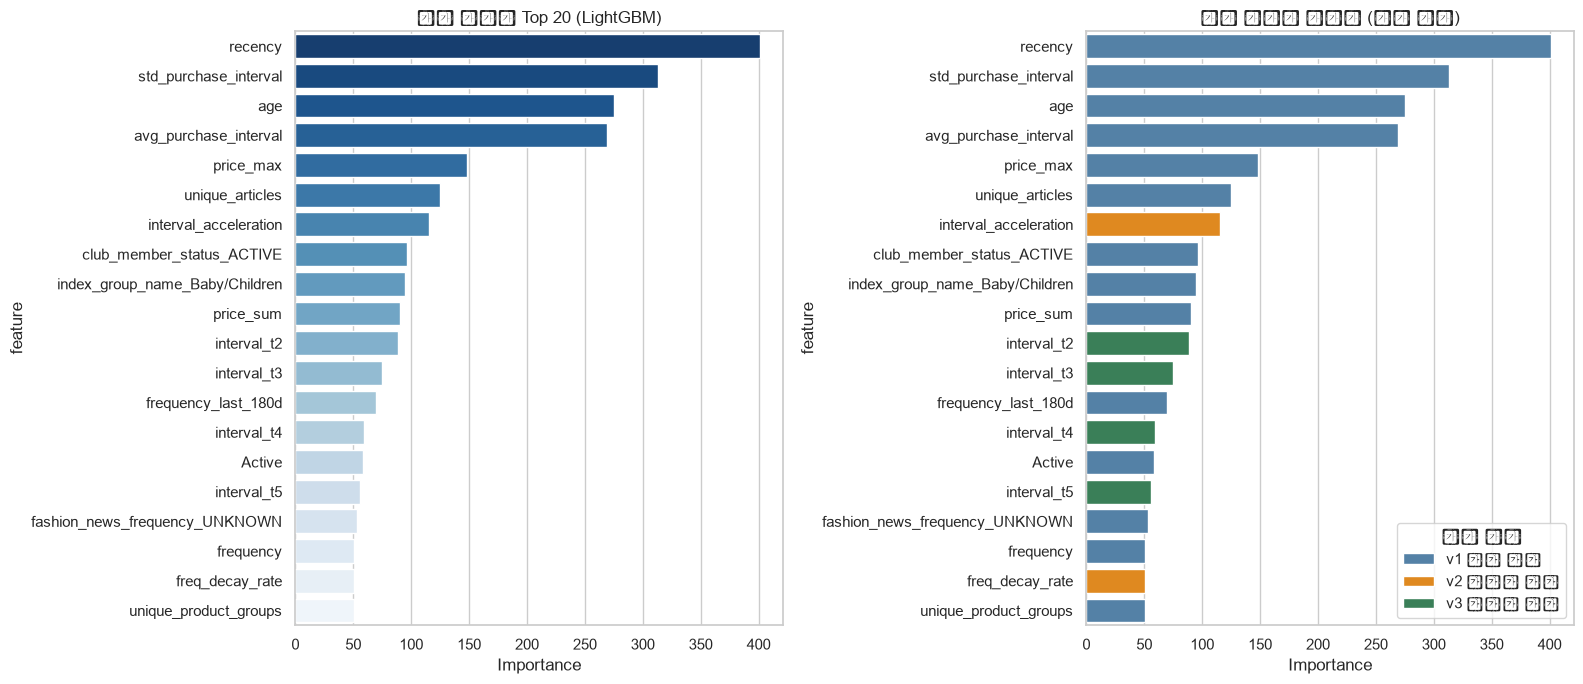

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# 좌: 전체 Top 20
top20 = importance_df.head(20)
sns.barplot(x='importance', y='feature', data=top20, ax=axes[0], palette='Blues_r')
axes[0].set_title('피처 중요도 Top 20 (LightGBM)', fontsize=12)
axes[0].set_xlabel('Importance')

# 우: v3 신규 피처 순위 강조
seq_cols = ['interval_t1','interval_t2','interval_t3','interval_t4','interval_t5']
new_v2_cols = ['freq_decay_rate','recent_price_ratio','unique_articles_last_90d',
               'diversity_decay_rate','interval_acceleration']

def get_category(f):
    if f in seq_cols: return 'v3 시퀀스 피처'
    elif f in new_v2_cols: return 'v2 트렌드 피처'
    else: return 'v1 기본 피처'

top20['category'] = top20['feature'].apply(get_category)
palette = {'v1 기본 피처': 'steelblue', 'v2 트렌드 피처': 'darkorange', 'v3 시퀀스 피처': 'seagreen'}
sns.barplot(x='importance', y='feature', data=top20,
            hue='category', palette=palette, ax=axes[1], dodge=False)
axes[1].set_title('피처 버전별 중요도 (색상 구분)', fontsize=12)
axes[1].set_xlabel('Importance')
axes[1].legend(title='피처 버전')

plt.tight_layout()
plt.show()


In [10]:
# EDA 상관관계 vs 모델 피처 중요도 교차 검증
eda_top5 = ['recency','unique_product_groups','unique_articles','frequency','frequency_last_180d']

print('--- EDA 상관관계 Top 5 vs 모델 피처 중요도 순위 ---')
print(f'{"피처":<30} {"EDA 순위":<12} {"모델 중요도 순위"}')
print('-' * 55)
for i, feat in enumerate(eda_top5):
    model_rank = importance_df[importance_df['feature']==feat]['rank'].values
    rank_str = str(model_rank[0]) if len(model_rank) > 0 else 'N/A'
    print(f'{feat:<30} {i+1}위{"":<9} {rank_str}위')
print()
print('→ EDA에서 중요하다고 발견한 피처와 모델이 중요하게 본 피처가 일치할수록')
print('  분석의 일관성이 높다는 것을 의미합니다.')


--- EDA 상관관계 Top 5 vs 모델 피처 중요도 순위 ---
피처                             EDA 순위       모델 중요도 순위
-------------------------------------------------------
recency                        1위          1위
unique_product_groups          2위          20위
unique_articles                3위          6위
frequency                      4위          18위
frequency_last_180d            5위          13위

→ EDA에서 중요하다고 발견한 피처와 모델이 중요하게 본 피처가 일치할수록
  분석의 일관성이 높다는 것을 의미합니다.


## 6. 최종 결론

### 6-1. 핵심 결론

> **거래 이력 기반 피처만으로는 고객 이탈 예측의 성능 천장이 AUC 0.848~0.849 수준입니다.**

피처 엔지니어링 3단계(RFM → 트렌드 → 시퀀스)와
하이퍼파라미터 튜닝 3가지 방법(GridSearch → RandomizedSearch → Optuna)을
모두 시도했으나 유의미한 성능 개선이 없었습니다.

특히 Optuna 베이지안 최적화가 기본 파라미터보다 낮은 성능을 보인 것은
튜닝 방법의 문제가 아니라 **데이터 자체의 정보량이 병목**임을 강하게 시사합니다.

### 6-2. 주요 발견

| 발견 | 내용 |
| :--- | :--- |
| 가장 강한 이탈 신호 | recency — 오래 안 산 고객일수록 이탈 가능성 높음 |
| 두 번째 신호 | unique_product_groups — 카테고리 다양성이 낮을수록 이탈 위험 |
| 트렌드/시퀀스 피처 | 기존 RFM과 중복된 정보 — 추가 성능 개선 없음 |
| 최적 모델 | CatBoost (AUC 0.8486) — 단, LightGBM 대비 학습시간 17배 |
| 실용적 최적 모델 | LightGBM (AUC 0.8480, 학습시간 3초) |

### 6-3. 성능 한계의 원인

```
있는 것  : 구매 횟수, 금액, 간격, 카테고리
없는 것  : 클릭 로그, 세션 시간, 앱 접속 기록, 장바구니 이탈
```

이탈은 '마지막 구매 이후 아무것도 안 했다'는 결과인데,
그 원인을 설명할 행동 데이터가 없어 모델의 학습 가능한 패턴에 한계가 생겼습니다.

### 6-4. 비즈니스 활용 방안

AUC 0.848은 실무에서 충분히 사용 가능한 수준입니다.

| 이탈 확률 구간 | 세그먼트 | 추천 액션 |
| :--- | :--- | :--- |
| 0.8 이상 | 이탈 임박 | 고가 쿠폰 + 개인화 추천 즉시 발송 |
| 0.6 ~ 0.8 | 이탈 위험 | 신상품 추천 이메일 + 등급 혜택 안내 |
| 0.3 ~ 0.6 | 관심 필요 | 재구매 타이밍 맞춘 자동 알림 |
| 0.3 미만 | 안전 | 액션 없음 (마케팅 비용 절감) |

### 6-5. 개선 방향

| 우선순위 | 방법 | 기대 효과 |
| :--- | :--- | :--- |
| 1순위 | 클릭/세션 행동 로그 추가 | AUC 0.90+ 가능 |
| 2순위 | 앙상블 (LightGBM + XGBoost) | AUC 0.001~0.003 소폭 개선 |
| 3순위 | LSTM/Transformer 시퀀스 모델 | 불확실, 작업량 많음 |


In [11]:
# 최종 결과 저장
os.makedirs('../results', exist_ok=True)

all_results.to_csv('../results/final_comparison.csv', index=False)
print('최종 비교 결과 저장 완료: ../results/final_comparison.csv')
print()
print('=' * 55)
print('프로젝트 최종 결론')
print('=' * 55)
print(f'분석 대상 고객 수  : 1,143,652명')
print(f'최종 최고 AUC      : 0.8486 (CatBoost, v3 베이스라인)')
print(f'실용적 최고 AUC    : 0.8480 (LightGBM, 학습시간 3초)')
print(f'시도한 피처 버전   : v1(16개) → v2(22개) → v3(26개)')
print(f'시도한 튜닝 방법   : RandomizedSearchCV, Optuna 베이지안 최적화')
print(f'결론               : 거래 이력 기반 피처의 성능 천장 확인')
print(f'한계 원인          : 행동 로그 데이터 부재')
print('=' * 55)


최종 비교 결과 저장 완료: ../results/final_comparison.csv

프로젝트 최종 결론
분석 대상 고객 수  : 1,143,652명
최종 최고 AUC      : 0.8486 (CatBoost, v3 베이스라인)
실용적 최고 AUC    : 0.8480 (LightGBM, 학습시간 3초)
시도한 피처 버전   : v1(16개) → v2(22개) → v3(26개)
시도한 튜닝 방법   : RandomizedSearchCV, Optuna 베이지안 최적화
결론               : 거래 이력 기반 피처의 성능 천장 확인
한계 원인          : 행동 로그 데이터 부재
